In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=2, suppress=True)

#####
<font color="#2c3e50" size="6"><div style="
    font-family: sans-serif;
    font-size: 1.2em;
    font-weight: 700;
    line-height: 1.2;
    background-color: #d9e6f2;
    border-radius: 8px;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    padding: 0.5em 1em;
    margin-top: 1em;
    margin-bottom: 0.6em;
    box-shadow: 0 2px 6px rgba(0,0,0,0.1);
" align="center">
5.1 Symmetric Matrices
</div></font>

In this final section, we will look at a special type of matrix called a symmetric matrix and see how, together with everything we have learned so far, it leads to applications such as dimensionality reduction, image compression, feature selection, and clustering.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition</strong><br> A matrix $A$ is called <strong> symmetric</strong> if $A^T=A$.
</div>



Symmetric matrices are necessarily square, and their entries are symmetric with respect to the main diagonal. Here are some examples of symmetric matrices, with pairs of symmetric entries highlighted:

$$
\require{color}
\newcommand{\hl}[1]{\bbox[orange, 2pt]{#1}}
\newcommand{\hly}[1]{\bbox[DarkTurquoise, 2pt]{#1}}
\newcommand{\hlg}[1]{\bbox[LimeGreen, 2pt]{#1}}
\begin{align*}
\left[
\begin{array}{}
2 & \hl{1}    \\ \hl{1}    & 3
\end{array}
\right]
\text{,}\qquad 
\left[
\begin{array}{}
2 & \hl{0}  & \hly{-2}  \\ \hl{0}    & 3 &  \hlg{3} \\ \hly{-2}& \hlg{3} & 0
\end{array}
\right]
\text{,}\qquad 
\left[
\begin{array}{}
2 & \hl{0}  & \hly{0}  \\ \hl{0}    & 3 &  \hlg{0} \\ \hly{0}& \hlg{0} & 0
\end{array}
\right]
\end{align*}$$

Symmetric matrices have an important property when they are diagonalized. Let's recall the diagonalization process and apply it to a symmetric matrix.

---
**<font color="red">Example 1</font>**

Diagonalize $A=\begin{bmatrix} 1 & 1 & 5 \\ 1 & 5 & 1 \\ 5& 1 & 1 \end{bmatrix}$ if possible.

**Solution.**

First, we find and solve the characteristic equation.

$$det(A-\lambda I)=\begin{vmatrix} 1-\lambda & 1 & 5 \\ 1 & 5-\lambda & 1 \\ 5& 1 & 1-\lambda \end{vmatrix}=-\lambda^3+7\lambda^2+16\lambda-112=-(\lambda+4)(\lambda-4)(\lambda-7)=0$$

We have three distinct eigenvalues, so we know that $A$ is diagonalizable. For each eigenvalue, we find a basis for the corresponding eigenspace:

$$ \lambda = -4 : {\bf v}_1=\begin{bmatrix} 1 \\ -2 \\ 1 \end{bmatrix} \text{,}\qquad \lambda = 4 : {\bf v}_2=\begin{bmatrix} -1 \\ 0 \\ 1 \end{bmatrix} \text{,}\qquad  \lambda = 7 : {\bf v}_3=\begin{bmatrix} 1 \\ 1 \\ 1 \end{bmatrix} $$

Observe that the three eigenvectors are mutually orthogonal, and therefore form an orthogonal basis for $\mathbb{R}^3$. As we have learned before, converting an orthogonal basis into an orthonormal basis can be useful for calculations. So, let's normalize them:

$$ \lambda = -4 : {\bf u}_1=\begin{bmatrix} 1/\sqrt{6} \\ -2/\sqrt{6} \\ 1/\sqrt{6} \end{bmatrix} \text{,}\qquad \lambda = 4 : {\bf u}_2=\begin{bmatrix} -1/\sqrt{2} \\ 0 \\ 1/\sqrt{2} \end{bmatrix} \text{,}\qquad  \lambda = 7 : {\bf u}_3=\begin{bmatrix} 1/\sqrt{3} \\ 1/\sqrt{3} \\ 1/\sqrt{3} \end{bmatrix} $$

Let $$P=\begin{bmatrix} {\bf u}_1& {\bf u}_2 & {\bf u}_3\end{bmatrix}=\begin{bmatrix} 1/\sqrt{6} & -1/\sqrt{2}&1/\sqrt{3}\\ -2/\sqrt{6}&0 & 1/\sqrt{3}\\ 1/\sqrt{6}&1/\sqrt{2}&1/\sqrt{3} \end{bmatrix} \quad \text{ and } \quad D =\begin{bmatrix} -4& 0&0 \\ 0 & 4 & 0 \\ 0& 0& 7\end{bmatrix}$$

Then $A=PDP^{-1}$. However, since $P$ is an orthogonal matrix, we can rewrite this as $$A=PDP^T$$


######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Spectral Theorem</b>
</div></font> 

In Example 1, we found that the eigenvectors corresponding to distinct eigenvalues were orthogonal. This is not a coincidence. In fact, this is one of the most crucial properties of symmetric matrices.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem </strong><br> If $A$ is symmetric, then any two eigenvectors corresponding to distinct eigenvalues are orthogonal.
</div>

**Proof.**

Let ${\bf v}_1$ and ${\bf v}_2$ be eigenvectors corresponding to the distinct eigenvalues $\lambda_1$ and $\lambda_2$, respectively. We want to show that ${\bf v}_1 \cdot {\bf v}_2=0$. Using the facts that $A^T=A$ and ${\bf x}\cdot {\bf y}={\bf x}^T{\bf y}$, we obtain

$$\lambda_1({\bf v}_1 \cdot {\bf v}_2)= (\lambda_1 {\bf v}_1 ) \cdot {\bf v}_2 = (A{\bf v}_1)\cdot {\bf v}_2=(A{\bf v}_1)^T {\bf v}_2=({\bf v}_1^T A^T) {\bf v}_2$$
$$ = ({\bf v}_1^T A) {\bf v}_2 = {\bf v}_1^T (A {\bf v}_2)={\bf v}_1 \cdot (A {\bf v}_2)={\bf v}_1 \cdot (\lambda_2 {\bf v}_2)=\lambda_2 ({\bf v}_1 \cdot {\bf v}_2)$$

Hence, $(\lambda_1-\lambda_2)({\bf v}_1 \cdot {\bf v}_2)=0$. However, $(\lambda_1-\lambda_2) \neq 0$, and so ${\bf v}_1 \cdot {\bf v}_2=0$.

The diagonalization obtained in Example 1 is a special type of diagonalization, important enough to have its own name.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition</strong><br> A square matrix $A$ is <strong>orthogonally diagonalizable</strong> if there exist an orthogonal matrix $P$ and a diagonal matrix $D$ such that $A=PDP^T$.
</div>


It is easy to see that every orthogonally diagonalizable matrix must be symmetric:
$$ A^T= (PDP^T)^T=(P^{T})^TD^TP^T=PDP^T=A$$

The next theorem shows that the converse is also true.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 2;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Spectral Theorem</strong><br> Let $A$ be an $n\times n$ symmetric matrix with real entries. Then: <br>
<strong>1.</strong> Every eigenvalue of $A$ is real.<br>
<strong>2.</strong> $\mathbb{R}^n$ has an orthonormal basis consisting of eigenvectors of $A$.<br>
<strong>3.</strong> $A$ is orthogonally diagonalizable.
</div>



The Spectral Theorem does not require the eigenvalues of a symmetric matrix to be distinct. If an eigenvalue has multiplicity greater than one, its eigenspace has the same dimension as its algebraic multiplicity. We can use the Gram–Schmidt process to obtain an orthonormal basis for that eigenspace. Eigenvectors belonging to different eigenspaces are automatically orthogonal.


Therefore, every real symmetric matrix $A$ can be orthogonally diagonalized as $A=PDP^T$. 

---
**<font color="red">Example 2</font>**

Orthogonally diagonalize $A=\begin{bmatrix} 2 & 1 & 1 \\ 1 & 2 & 1 \\ 1& 1 & 2 \end{bmatrix}$

**Solution.**

The characteristic equation for $A$ is $$-(\lambda-1)^2(\lambda-4)=0$$

For $\lambda=4$, a basis for the corresponding eigenspace consists of one vector $$\left\{\begin{bmatrix} 1 \\ 1 \\1 \end{bmatrix} \right\}$$

For $\lambda=1$, the usual methods for finding a basis for the eigenspace give $$\left\{\begin{bmatrix} -1 \\ 0 \\1 \end{bmatrix}, \begin{bmatrix} -1 \\ 1 \\0 \end{bmatrix} \right\}$$
The two vectors in this basis are not orthogonal, but we can apply the Gram–Schmidt process to obtain an orthogonal basis for the same eigenspace:

$$\left\{\begin{bmatrix} -1 \\ 0 \\1 \end{bmatrix}, \begin{bmatrix} -1 \\ 2 \\-1 \end{bmatrix} \right\}$$

Next, we normalize the three basis vectors and form matrices $P$ and $D$:

$$P=\begin{bmatrix} 1/\sqrt{3} & -1/\sqrt{2} & -1/\sqrt{6} \\ 1/\sqrt{3} & 0 & 2/\sqrt{6}\\ 1/\sqrt{3} & 1/\sqrt{2} & -1/\sqrt{6}\end{bmatrix} \text{, and } D=\begin{bmatrix} 4 & 0 &0\\ 0 & 1 & 0 \\ 0& 0& 1\end{bmatrix}$$

Verify that the columns of $P$ are orthonormal.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Geometric Interpretation</b>
</div></font> 



The factorization $A=PDP^T$ has a useful geometric interpretation. For a vector $\bf x$, we can write $$A{\bf x}=PDP^T{\bf x}$$ The multiplication can be viewed as three steps:
$$ \large{{\bf x} \stackrel{P^T}{\longrightarrow}P^T{\bf x}\stackrel{D}{\longrightarrow}DP^T{\bf x}\stackrel{P}{\longrightarrow}PDP^T{\bf x}}$$

**Step 1: Change the coordinates**

The matrix $P^T$ changes the coordinates of ${\bf x}$ from the standard basis to the orthonormal basis formed by the eigenvectors of $A$.

**Step 2: Scale the coordinates**

Since $D$ is diagonal, multiplication by $D$ simply multiplies each eigenvector coordinate by its corresponding eigenvalue.

**Step 3: Change the coordinates back**

Finally, multiplication by $P$ converts the vector back to the standard coordinate system.

Thus, the transformation represented by a symmetric matrix can be understood as changing to an eigenvector coordinate system, scaling each coordinate independently, and then returning to the standard coordinate system.

<center> <img src="data:image/png;base64,  ...
 " width="80%"> </center>

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> Recall that since $P$ is an orthogonal matrix, the transformations ${\bf x} \rightarrow P{\bf x}$ and ${\bf x} \rightarrow P^T{\bf x}$ represent rotations, reflections, or combinations of the two.
</div>



######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Spectral Decomposition</b>
</div></font> 

The Spectral Theorem allows us to write any symmetric matrix $A$ as a product $PDP^T$, where $P$ is an orthogonal matrix whose columns are normalized eigenvectors of $A$ and $D$ is a diagonal matrix containing the corresponding eigenvalues. This allows us to rewrite $A$ as a sum of special matrices:

$$A=PDP^T=\begin{bmatrix} {\bf v}_1 & \cdots &  {\bf v}_n \end{bmatrix} \begin{bmatrix} \lambda_1 & \cdots & 0 \\ \vdots & \ddots & \vdots \\ 0 & \cdots & \lambda_n\end{bmatrix} \begin{bmatrix} {\bf v}_1^T \\ \vdots \\ {\bf v}_n^T\end{bmatrix} = \begin{bmatrix} \lambda_1{\bf v}_1 & \cdots &  \lambda_n{\bf v}_n \end{bmatrix} \begin{bmatrix} {\bf v}_1^T \\ \vdots \\ {\bf v}_n^T\end{bmatrix}= \lambda_1{\bf v}_1{\bf v}_1^T+ \cdots + \lambda_n{\bf v}_n{\bf v}_n^T$$

This is called the **spectral decomposition** of $A$. Each term $\lambda_i{\bf v}_i{\bf v}_i^T$ has rank 1 when $\lambda_i \neq 0$. Moreover, because the eigenvectors are normalized, ${\bf v}_i{\bf v}_i^T$ is the orthogonal projection matrix onto the one-dimensional subspace spanned by the corresponding eigenvector ${\bf v}_i$. Therefore, for a given vector ${\bf x}$, the spectral decomposition expresses $A{\bf x}$ as a sum of components along the eigenvector directions.


<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> In linear algebra, the "spectrum" of a matrix is the set of its eigenvalues. The term comes from physics, where a spectrum describes the distribution of light or other phenomena according to quantities such as frequency. In linear algebra, the eigenvalues play an analogous role.
</div>

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> The product  ${\bf x}{\bf y}^T$ is called the <strong> outer product</strong> of ${\bf x}$ and ${\bf y}$. 
</div>

---

**<font color="red">Example 3</font>**

Construct the spectral decomposition of $A=\begin{bmatrix} 12 & 2 & 5 \\ 2 & 11 & 8 \\ 5 & 8 & 7 \end{bmatrix}$ using Python.

**Solution.**

We start by finding the eigenvalues and eigenvectors. Since the eigenvalues are not necessarily sorted, let's arrange them in descending order, and reorder the eigenvectors accordingly as well using `np.argsort()`.

In [11]:
A=np.array([[12,2,5],[2,11,8],[5,8,7]])
eigenvalues, P = np.linalg.eig(A)

order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
P = P[:, order]

print(P)

[[-0.52 -0.82 -0.25]
 [-0.63  0.56 -0.54]
 [-0.58  0.13  0.8 ]]


In [12]:
print(eigenvalues)

[20.06  9.87  0.07]


To compute the outer product of two vectors, we can use the `np.outer()` function.

In [13]:
P0=np.outer(P[:,0], P[:,0])
print(P0)

[[0.27 0.32 0.3 ]
 [0.32 0.39 0.37]
 [0.3  0.37 0.34]]


In [14]:
P1=np.outer(P[:,1], P[:,1])
print(P1)

[[ 0.67 -0.46 -0.1 ]
 [-0.46  0.31  0.07]
 [-0.1   0.07  0.02]]


In [15]:
P2=np.outer(P[:,2], P[:,2])
print(P2)

[[ 0.06  0.13 -0.2 ]
 [ 0.13  0.29 -0.44]
 [-0.2  -0.44  0.65]]


Let's multiply each matrix by its corresponding eigenvalue and add the resulting matrices to verify that their sum equals $A$.

In [17]:
print(eigenvalues[0]*P0 + eigenvalues[1]*P1 + eigenvalues[2]*P2)

[[12.  2.  5.]
 [ 2. 11.  8.]
 [ 5.  8.  7.]]


---

As we can see, the spectral decomposition gives back $A$.

Notice that one of the eigenvalues is very small, approximately $0.066$. Therefore, the corresponding term in the spectral decomposition has a relatively small effect on the resulting matrix. If we remove this term, we obtain an approximation of the original matrix that uses only two eigenvector directions. In other words, the approximation has rank 2, so its column space is two-dimensional. This is the basic idea behind dimensionality reduction: if some directions contribute much less than others, we may be able to represent the data using only the most important directions.

Suppose we denote the approximation of $A$ by $B$. Then, for any vector ${\bf x}$, the vector $B{\bf x}$ provides a good approximation of $A{\bf x}$, because the discarded eigenvalue is small. In fact, $B{\bf x}$ is the orthogonal projection of $A{\bf x}$ onto the two-dimensional subspace spanned by the first two eigenvectors.

Why does this work? Since the third eigenvalue is small, $A$ strongly compresses the component of ${\bf x}$ in the direction of the third eigenvector. As a result, the vectors $A{\bf x}$ tend to lie close to the plane spanned by the first two eigenvectors. Therefore, $A{\bf x}$ is close to its projection $B{\bf x}$ onto that plane.

---

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #aca210;
    background-color: rgba(190,190,20,0.16);
    margin: 0.4em 0;
">
<strong>🛠️ <font color="magenta">Practice: </font> </strong> Compute the matrix $B$ which approximates the matrix $A$ from Example 3 by retaining the two largest eigenvalues in absolute value. Compare the entries of $A$ and $B$.
</div>

---
**<font color="red">Example 4</font>**

Use the Spectral Theorem to construct a $2\times 2$ matrix $A$ with eigenvectors ${\bf v}_1=\begin{bmatrix} 1/\sqrt{5} \\ 2/\sqrt{5}\end{bmatrix}, {\bf v}_2=\begin{bmatrix}2/\sqrt{5}\\ -1/\sqrt{5}\end{bmatrix}$ and corresponding eigenvalues $5$ and $1/10$. Then approximate the resulting matrix using the first eigenvector direction. Plot the images of the unit circle under both $A$ and its approximation.

**Solution.**

The given eigenvectors are orthonormal. Therefore, the Spectral Theorem gives $A=5{\bf v}_1{\bf v}_1^T+\frac{1}{10}{\bf v}_2{\bf v}_2^T$. Using only the first eigenvector direction gives the approximation $B=5{\bf v}_1{\bf v}_1^T$.

In [24]:
v1=np.array([1/np.sqrt(5), 2/np.sqrt(5)])
v2=np.array([2/np.sqrt(5), -1/np.sqrt(5)])

A=5*np.outer(v1, v1)+0.1*np.outer(v2,v2)
B=5*np.outer(v1, v1)

print(A)
print('\n',B)

[[1.08 1.96]
 [1.96 4.02]]

 [[1. 2.]
 [2. 4.]]


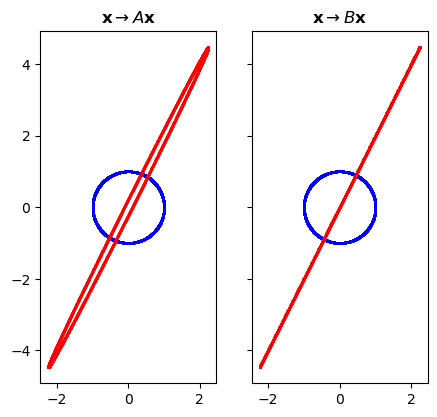

In [33]:
fig, ax = plt.subplots(1, 2, sharey=True, figsize=(5,5))
ax[0].set_aspect(1)
ax[1].set_aspect(1)

# Unit circle (blue)
t = np.linspace(0, 2*np.pi, 3000)
x=np.cos(t)
y=np.sin(t)
ax[0].scatter(x,y, s=1, color='b')
ax[1].scatter(x,y, s=1, color='b')

# Images of the unit circle(red)
vec=np.array([x,y])
image_A=A@vec
ax[0].scatter(image_A[0],image_A[1], s=1, color='r')
ax[0].set_title(r'${\bf x}\rightarrow  A\bf x$')
image_B=B@vec
ax[1].scatter(image_B[0],image_B[1], s=1, color='r')
ax[1].set_title(r'${\bf x}\rightarrow  B\bf x$')

plt.show()

---

This example illustrates dimensionality reduction particularly clearly. The eigenvalue $1/10$ is small, so the transformation strongly compresses vectors along the corresponding eigenvector direction. In contrast, the eigenvalue $5$ produces strong stretching along the other eigenvector direction. Therefore, the direction corresponding to $1/10$ contributes relatively little to the transformation. By discarding this direction, we obtain a rank-1 approximation that captures most of the action of $A$.

Many real-world datasets contain hundreds or thousands of variables, but much of the information may be concentrated in only a few directions. Spectral decomposition allows us to identify the directions that contribute most to the data and discard those whose contributions are relatively small.

This idea allows us to replace a high-dimensional representation with a lower-dimensional one while preserving much of the important information. Later, we will develop this idea further using the singular value decomposition (SVD) and principal component analysis (PCA).

######
<font color="#0fbf0f" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Exercises</b>
</div></font> 

**1.** 
>Orthogonally diagonalize the following matrices. That is, find $P$ and $D$ such that the given matrix is equal to $PDP^T$ <br><br>
>***a.*** $\begin{bmatrix} 1 & 2 \\ 2 & 1\end{bmatrix}; \quad \quad \quad$
>***b.*** $\begin{bmatrix} 3 & 4 \\ 4 & 9\end{bmatrix}$


**2.** 
>Orthogonally diagonalize the following matrices. That is, find $P$ and $D$ such that the given matrix is equal to $PDP^T$ <br><br>
>***a.*** $\begin{bmatrix} 5 & 0 & 0 \\ 0&  1& 3 \\ 0 & 3 & 1\end{bmatrix}$ (The eigenvalues are $-2$, $4$ and $5$)<br><br>
>***b.*** $\begin{bmatrix} 2 & 0 & 0 & 1\\ 0&  1& 0 & 0\\ 0 & 0 & 1 & 0\\ 1 & 0 & 0 & 2\end{bmatrix}$ (The distinct eigenvalues are $1$ and $3$)<br><br>


**3.**
>Find the spectral decomposition of each matrix in problem 1 and 2.


**4.**
>Construct a matrix with the following orthonormal eigenvectors and corresponding eigenvalues:<br><br>
>***a.*** $\lambda_1=1$, ${\bf v}_1 = \begin{bmatrix} 0.6 \\ 0.8 \end{bmatrix}$ and $\lambda_2=4$, ${\bf v}_2 = \begin{bmatrix} 0.8 \\ -0.6 \end{bmatrix}$<br><br>
>***b.*** $\lambda_1=-2$, ${\bf v}_1 = \begin{bmatrix} 0 \\ 1 \\0 \end{bmatrix}$,  $\lambda_2=0$, ${\bf v}_2 = \begin{bmatrix} 1/2 \\ 0 \\ \sqrt{3}/2 \end{bmatrix}$, and $\lambda_3=5$, ${\bf v}_3 = \begin{bmatrix} \sqrt{3}/2 \\ 0\\ -1/2 \end{bmatrix}$

**5.**
>Suppose $A$ is invertible and orthogonally diagonalizable. Show that $A^{-1}$ is also orthogonally diagonalizable.

**6.**
>Show that for any matrix $A$, both $A^TA$ and $AA^T$ are symmetric.

**7.**
> Use Python for this problem. Let $A =\begin{bmatrix} 3 & 1 & 4 \\ 1 & 10 & 1 \\ 4 & 1 & 5 \end{bmatrix}$, ${\bf x}_1=\begin{bmatrix} 5 \\ 4  \\ -7  \end{bmatrix}$, ${\bf x}_2=\begin{bmatrix} 7 \\ 3  \\ -8  \end{bmatrix}$, and ${\bf x}_3=\begin{bmatrix} 7 \\ 5  \\ -5  \end{bmatrix}$.<br><br>
> ***a.*** Let $B$ be the approximation of $A$ obtained by retaining only the two eigenvalues with the largest absolute values and their corresponding eigenvectors in the spectral decomposition. Find $B$. <br><br>
> ***b.*** Find the images of the vectors ${\bf x}_1$,  ${\bf x}_2$, and  ${\bf x}_3$ under $A$, and find the pairwise distances between these images.<br><br>
> ***c.*** Find the images of the vectors ${\bf x}_1$,  ${\bf x}_2$, and  ${\bf x}_3$ under $B$, and find the pairwise distances between these images. Compare these distances with the corresponding distances under $A$.<br><br>
> ***d.*** Let $C$ be the matrix obtained by retaining the two eigenvalues with the smallest absolute values and their corresponding eigenvectors in the spectral decomposition of $A$. Find the images of the vectors  ${\bf x}_1$,  ${\bf x}_2$, and  ${\bf x}_3$ under $C$, and find the pairwise distances between these images.  Compare these distances with the corresponding distances under $A$.